# Jeux globaux — la sélection d'équilibre par le tremble

> Carnet **11e** de la série GameTheory. Prolongement des carnets [**11**](GameTheory-11-BayesianGames-Python.ipynb) (jeux bayésiens) et [**10**](GameTheory-10-ForwardInduction-SPE-Python.ipynb) (induction en avant).

Un jeu de coordination a **plusieurs équilibres de Nash** : qui coordonne sur (T, L) et qui sur (B, R) ? L'**induction en avant** (carnet 10) lève cette indétermination **en forme extensive** — elle élimine, le long de l'arbre, les comportements irrationnels *ex ante*. Les **jeux globaux** (Morris 1994) lèvent la *même* indétermination dans un jeu **simultané**, sans aucun arbre : par la structure des **croyances sur un état commun**.

Chaque joueur observe un **signal bruyé** d'un état commun — le fondamental plus un **tremble** privé. Quand le tremble s'amenuise, l'équilibre de Nash bayésien, alors **unique**, **sélectionne** l'issue ancrée au fondamental. Ce carnet construit ce mécanisme de bout en bout et **le mesure** : la coupure d'équilibre converge vers la règle fondamentale, et la décision d'équilibre redevient exacte.

## 1. Le modèle — un état commun, des signaux bruyés

Un **état commun** `θ` (la valeur vraie de l'actif) est tiré une fois, inconnu des joueurs. Chacun observe un **signal privé** `x_i = θ + ε_i` : le fondamental plus un **tremble** `ε_i` (bruit privé, indépendant). Investir coûte `c` et rapporte `θ`. La règle **fondamentale** — celle qu'on suivrait avec information complète — est donc :

> **investir  ⟺  `θ > c`**

In [1]:
import numpy as np
import math
import matplotlib.pyplot as plt
np.random.seed(21932)

def Phi(z):
    """Fonction de répartition de N(0,1), sans dépendance externe (stdlib)."""
    return 0.5 * (1.0 + math.erf(z / math.sqrt(2.0)))

# --- Paramètres du jeu global ---
MU      = 0.8    # moyenne de l'état commun theta
SIGMA_T = 0.5    # écart-type de theta (incertitude sur le fondamental)
COUT    = 1.0    # coût d'investir
N       = 20000  # nombre de joueurs (limite continuum)

print(f"État commun   θ ~ N({MU}, {SIGMA_T}²)")
print(f"Coût d'investir = {COUT}")
print(f"Règle fondamentale (info complète) : investir  ⟺  θ > {COUT}")
print(f"P(θ > {COUT}) = {1.0 - Phi((COUT - MU) / SIGMA_T):.4f}  "
      f"(fraction qui investirait à info complète)")

État commun   θ ~ N(0.8, 0.5²)
Coût d'investir = 1.0
Règle fondamentale (info complète) : investir  ⟺  θ > 1.0
P(θ > 1.0) = 0.3446  (fraction qui investirait à info complète)


## 2. L'équilibre de Nash bayésien — une coupure unique

Chaque joueur raisonne en **bayésien** (la mécanique du carnet 11) : de son signal `x_i`, elle déduit sa croyance sur l'état, `E[θ | x_i]`. L'équilibre de Nash bayésien est une **stratégie de coupure** : *investir si et seulement si* `x_i ≥ c*`. Le **tremble** (`σ_ε > 0`) est précisément ce qui rend la coupure **unique** — sans lui, au point exact du seuil, le jeu redevient indéterminé.

La coupure d'équilibre est le point où la joueuse est **indifférente**, c'est-à-dire où sa croyance atteint le coût. Avec `x = θ + ε` et `E[θ | x] = μ + λ(x − μ)`, `λ = σ_θ² / (σ_θ² + σ_ε²)`, on obtient :

In [2]:
def coupure_equilibre(sigma_eps):
    """Coupure c* de l'équilibre de Nash bayésien unique.

    Indifférence de la joueuse :  E[θ | x] = COUT.
    E[θ | x] = MU + lambda (x - MU),  lambda = SIGMA_T² / (SIGMA_T² + sigma_eps²).
    D'où  c* = MU + (COUT - MU) / lambda
         = MU + (COUT - MU) * (1 + sigma_eps² / SIGMA_T²).
    """
    lam = SIGMA_T**2 / (SIGMA_T**2 + sigma_eps**2)
    return MU + (COUT - MU) / lam

print("La coupure d'équilibre dépend du tremble :")
for se in [0.5, 0.3, 0.2, 0.1, 0.05, 0.02, 0.01]:
    print(f"   σ_ε = {se:4.2f}   →   c* = {coupure_equilibre(se):.4f}")
print(f"\n   Limite σ_ε → 0 :  c* → {MU + (COUT - MU):.4f}  "
      f"(= le coût COUT : la règle fondamentale)")
print("\n   Un signal plus bruité pousse à exiger un signal plus net avant "
      "d'investir ; la prudence s'efface quand le tremble disparaît.")

La coupure d'équilibre dépend du tremble :
   σ_ε = 0.50   →   c* = 1.2000
   σ_ε = 0.30   →   c* = 1.0720
   σ_ε = 0.20   →   c* = 1.0320
   σ_ε = 0.10   →   c* = 1.0080
   σ_ε = 0.05   →   c* = 1.0020
   σ_ε = 0.02   →   c* = 1.0003
   σ_ε = 0.01   →   c* = 1.0001

   Limite σ_ε → 0 :  c* → 1.0000  (= le coût COUT : la règle fondamentale)

   Un signal plus bruité pousse à exiger un signal plus net avant d'investir ; la prudence s'efface quand le tremble disparaît.


## 3. La sélection — mesurée

La **sélection** est ce que la coupure d'équilibre *accomplit* quand le tremble s'amenuise : l'équilibre **unique** converge vers la règle fondamentale. On la mesure de deux façons — la coupure `c*` elle-même, et la **précision** de la décision d'équilibre : décide-t-on d'investir *exactement* quand le fondamental le justifie ?

In [3]:
print("   σ_ε      c* (coupure)    précision de la décision d'équilibre")
print("   ------   -------------   -------------------------------------")
for se in [0.5, 0.3, 0.2, 0.1, 0.05, 0.02, 0.01, 0.001]:
    cstar = coupure_equilibre(se)
    theta = np.random.normal(MU, SIGMA_T, N)
    x     = theta + np.random.normal(0.0, se, N)
    decide_eq   = x >= cstar        # règle d'équilibre (coupure unique)
    decide_fond = theta > COUT      # règle fondamentale (info complète)
    prec = np.mean(decide_eq == decide_fond)
    print(f"   {se:6.3f}   {cstar:13.4f}   {prec:20.4f}")
print("\n   →  c* → COUT  et  précision → 1 :  l'équilibre unique "
      "récolte la règle fondamentale quand le tremble s'amenuise.")

   σ_ε      c* (coupure)    précision de la décision d'équilibre
   ------   -------------   -------------------------------------
    0.500          1.2000                 0.7748
    0.300          1.0720                 0.8427
    0.200          1.0320                 0.8890
    0.100          1.0080                 0.9412
    0.050          1.0020                 0.9695
    0.020          1.0003                 0.9867
    0.010          1.0001                 0.9942
    0.001          1.0000                 0.9996

   →  c* → COUT  et  précision → 1 :  l'équilibre unique récolte la règle fondamentale quand le tremble s'amenuise.


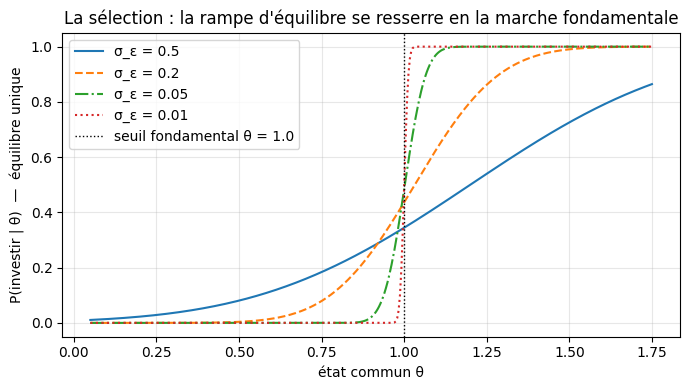

In [4]:
# P(investir | θ) sous la règle d'équilibre : une RAMPE qui se resserre en un MARCHÉ
def Phi_arr(z):
    return 0.5 * (1.0 + np.vectorize(math.erf)(z / np.sqrt(2.0)))

theta_grid = np.linspace(MU - 1.5 * SIGMA_T, COUT + 1.5 * SIGMA_T, 400)
plt.figure(figsize=(7, 4))
for se, sty in zip([0.5, 0.2, 0.05, 0.01], ['-', '--', '-.', ':']):
    cstar = coupure_equilibre(se)
    p_inv = 1.0 - Phi_arr((cstar - theta_grid) / se)   # P(x ≥ c* | θ)
    plt.plot(theta_grid, p_inv, sty, label=f"σ_ε = {se}")
plt.axvline(COUT, color='k', lw=1, ls=':', label=f"seuil fondamental θ = {COUT}")
plt.xlabel("état commun θ")
plt.ylabel("P(investir | θ)  —  équilibre unique")
plt.title("La sélection : la rampe d'équilibre se resserre en la marche fondamentale")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 4. Ce que la sélection par jeu global accomplit (vs induction en avant)

L'induction en avant (carnet 10) sélectionne **le long d'un arbre** : elle supprime les équilibres soutenus par une menace ou une action irrationnelle *ex ante*. Le jeu global sélectionne **sans aucun arbre** — le jeu est joué en une fois, simultanément. La sélection y naît de la **structure des croyances** : un état commun, des signaux privés, et le tremble qui rend l'équilibre unique et continu.

Deux machines de sélection, deux structures : **l'arbre** (carnet 10) vs **les croyances sur un état commun** (ici). C'est ce que le tremble *accomplit* que l'induction en avant ne peut pas : lever l'indétermination d'un jeu **simultané**.

## 5. Exercices

**Exercice 1** — *Coupure d'équilibre.* Généraliser `coupure_equilibre` en une fonction `coupure(MU, SIGMA_T, COUT, sigma_eps)` qui renvoie la coupure `c*` pour des paramètres arbitraires.

**Exercice 2** — *Le tremble est essentiel.* Que se passe-t-il à l'équilibre quand `σ_ε = 0` **exactement** (information complète) et que `θ` tombe pile sur le seuil `c` ? Pourquoi le tremble est-il ce qui rend la coupure unique ?

**Exercice 3** — *Complémentarité stratégique.* Ajouter au retour d'investir un terme `γ · ā` (la fraction d'investisseurs lève mon retour). Poser le point fixe `(c*, p*)` de la limite continuum et le résoudre numériquement : montrer que la solution reste **unique** pour tout `σ_ε > 0`.

In [5]:
def coupure(MU, SIGMA_T, COUT, sigma_eps):
    """Exercice 1 — renvoyer la coupure c* de l'équilibre de Nash bayésien unique."""
    # TODO étudiant
    return None
print("Exercice 1 à compléter :  coupure(MU, SIGMA_T, COUT, sigma_eps)")

Exercice 1 à compléter :  coupure(MU, SIGMA_T, COUT, sigma_eps)


In [6]:
def pourquoi_le_tremble():
    """Exercice 2 — renvoyer une chaîne expliquant le rôle du tremble."""
    # TODO étudiant
    return None
print("Exercice 2 à compléter :  pourquoi_le_tremble()")

Exercice 2 à compléter :  pourquoi_le_tremble()


In [7]:
def point_fixe_continuum(gamma, sigma_eps):
    """Exercice 3 — résoudre le point fixe (c*, p*) de la limite continuum.

    p  = P(θ + ε ≥ c*)            (taux d'investissement d'équilibre)
    c* = COUT - gamma * p          (indifférence avec complémentarité)
    Renvoyer la solution unique (c*, p) pour sigma_eps > 0.
    """
    # TODO étudiant
    return None
print("Exercice 3 à compléter :  point_fixe_continuum(gamma, sigma_eps)")

Exercice 3 à compléter :  point_fixe_continuum(gamma, sigma_eps)


## Références

- **Morris, A. (1994)** — *Continuous games and theory of rational behaviour* : les jeux globaux, l'équilibre unique sous tremble, et la sélection par amenuisement du tremble.
- **Harsanyi, J. C. (1987–88)** — *Rational Behaviour and Equilibrium Convolution of Games* : la perturbation (tremble) des jeux et la sélection d'équilibres.
- Carnets de cette série : [10 — Induction en avant / SPE](GameTheory-10-ForwardInduction-SPE-Python.ipynb), [11 — Jeux bayésiens](GameTheory-11-BayesianGames-Python.ipynb).